<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2027%20-%20%C3%81rvores%20de%20Decis%C3%A3o%20-%20Algoritmos%20Cl%C3%A1ssicos%20de%20Constru%C3%A7%C3%A3o%20de%20%C3%81rvore%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 27 - Notebook: Árvores de Decisão Clássicas (ID3 / C4.5 / CART) no Diagnóstico da HRS

Este notebook implementa do zero em Python um construtor de **Árvore de Decisão Binária** com suporte aos três critérios clássicos:
- **Entropia / Ganho de Informação** (`entropy` — base do ID3);
- **Razão de Ganho** (`gain_ratio` — base do C4.5 para atributos contínuos);
- **Impureza de Gini** (`gini` — base do CART).

Aplicamos o modelo para diagnosticar automaticamente 4 regimes operacionais da HRS (`Nominal`, `Falha_Chiller_Termica`, `Sobrepressao_Cascata`, `Vazamento_H2`) e plotamos as fronteiras de decisão **reais** extraídas da árvore treinada.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import Counter
from typing import Optional, Tuple
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
np.random.seed(42)

### 1. Geração do Dataset Sintético de Diagnóstico da Estação de Hidrogênio

In [2]:
def gerar_dataset_diagnostico_hrs(n_por_classe: int = 150) -> pd.DataFrame:
    registros = []
    # 1. Nominal
    for _ in range(n_por_classe):
        registros.append([
            np.random.normal(340, 15), np.random.normal(25, 8),
            np.abs(np.random.normal(2, 1.5)), np.random.normal(720, 30), "Nominal"
        ])
    # 2. Falha Chiller HEX-201 / Sobreaquecimento
    for _ in range(n_por_classe):
        registros.append([
            np.random.normal(350, 15), np.random.normal(76, 7),
            np.abs(np.random.normal(3, 1.5)), np.random.normal(740, 35), "Falha_Chiller_Termica"
        ])
    # 3. Sobrepressao Cascata TK-101 / PT-201
    for _ in range(n_por_classe):
        registros.append([
            np.random.normal(405, 14), np.random.normal(38, 9),
            np.abs(np.random.normal(3, 1.5)), np.random.normal(885, 25), "Sobrepressao_Cascata"
        ])
    # 4. Vazamento H2 (> 25% LIE ou pre-alarme)
    for _ in range(n_por_classe):
        registros.append([
            np.random.normal(325, 20), np.random.normal(32, 10),
            np.random.uniform(16, 45), np.random.normal(700, 40), "Vazamento_H2"
        ])
    df = pd.DataFrame(registros, columns=["PT_101_bar", "TT_101_degC", "AT_101_pctLIE", "PT_201_bar", "Classe"])
    return df.sample(frac=1.0, random_state=42).reset_index(drop=True)

df = gerar_dataset_diagnostico_hrs(150)
print(f"Dataset gerado: {len(df)} amostras | Classes: {df['Classe'].value_counts().to_dict()}")
display(df.head())

Dataset gerado: 600 amostras | Classes: {'Nominal': 150, 'Sobrepressao_Cascata': 150, 'Vazamento_H2': 150, 'Falha_Chiller_Termica': 150}


,PT_101_bar,TT_101_degC,AT_101_pctLIE,PT_201_bar,Classe
0,345.760982,24.738442,1.101163,717.326399,Nominal
1,422.040219,51.691844,4.497466,874.209492,Sobrepressao_Cascata
2,321.211727,16.597524,32.822576,779.335449,Vazamento_H2
3,348.206461,23.382459,1.673478,752.963306,Nominal
4,352.562982,74.712117,3.027651,752.165360,Falha_Chiller_Termica


### 2. Implementação de Entropia (ID3), Razão de Ganho (C4.5) e Gini (CART)

In [3]:
def entropia_shannon(y: np.ndarray) -> float:
    _, counts = np.unique(y, return_counts=True)
    probs = counts / len(y)
    return float(-np.sum(probs * np.log2(probs + 1e-12)))

def impureza_gini(y: np.ndarray) -> float:
    _, counts = np.unique(y, return_counts=True)
    probs = counts / len(y)
    return float(1.0 - np.sum(probs ** 2))

class TreeNode:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, impurity=0.0, samples=0):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.impurity = impurity
        self.samples = samples

class ArvoreDecisaoClassica:
    def __init__(self, criterion: str = "gini", max_depth: int = 4, min_samples_split: int = 5):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root: Optional[TreeNode] = None
        self.feature_names = []

    def _impureza(self, y: np.ndarray) -> float:
        return impureza_gini(y) if self.criterion == "gini" else entropia_shannon(y)

    def _melhor_divisao(self, X: np.ndarray, y: np.ndarray) -> Tuple[Optional[int], Optional[float], float]:
        n_samples, n_features = X.shape
        imp_pai = self._impureza(y)
        melhor_score = -1.0
        melhor_feat, melhor_thresh = None, None

        for feat in range(n_features):
            valores = np.unique(X[:, feat])
            limiares = (valores[:-1] + valores[1:]) / 2.0
            for thresh in limiares:
                mask_esq = X[:, feat] <= thresh
                n_esq = int(np.sum(mask_esq))
                n_dir = n_samples - n_esq
                if n_esq == 0 or n_dir == 0:
                    continue
                p_esq, p_dir = n_esq / n_samples, n_dir / n_samples
                imp_filhos = p_esq * self._impureza(y[mask_esq]) + p_dir * self._impureza(y[~mask_esq])
                ganho = imp_pai - imp_filhos
                if self.criterion == "gain_ratio":
                    split_info = -(p_esq * np.log2(p_esq + 1e-12) + p_dir * np.log2(p_dir + 1e-12))
                    score = ganho / max(split_info, 1e-9)
                else:
                    score = ganho
                if score > melhor_score:
                    melhor_score = score
                    melhor_feat = feat
                    melhor_thresh = float(thresh)
        return melhor_feat, melhor_thresh, melhor_score

    def _construir(self, X: np.ndarray, y: np.ndarray, depth: int) -> TreeNode:
        imp = self._impureza(y)
        classe_majoritaria = Counter(y).most_common(1)[0][0]

        if depth >= self.max_depth or len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return TreeNode(value=classe_majoritaria, impurity=imp, samples=len(y))

        feat, thresh, score = self._melhor_divisao(X, y)
        if feat is None or score <= 1e-6:
            return TreeNode(value=classe_majoritaria, impurity=imp, samples=len(y))

        mask_esq = X[:, feat] <= thresh
        left = self._construir(X[mask_esq], y[mask_esq], depth + 1)
        right = self._construir(X[~mask_esq], y[~mask_esq], depth + 1)
        return TreeNode(feature=feat, threshold=thresh, left=left, right=right, impurity=imp, samples=len(y))

    def fit(self, X: np.ndarray, y: np.ndarray, feature_names=None):
        self.feature_names = feature_names or [f"X{i}" for i in range(X.shape[1])]
        self.root = self._construir(X, y, depth=0)

    def _predict_one(self, x: np.ndarray, node: TreeNode):
        if node.value is not None:
            return node.value
        if x[node.feature] <= node.threshold:
            return self._predict_one(x, node.left)
        return self._predict_one(x, node.right)

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.array([self._predict_one(x, self.root) for x in X])

    def imprimir_regras(self, node: Optional[TreeNode] = None, indent: str = ""):
        if node is None:
            node = self.root
        if node.value is not None:
            print(f"{indent}-> DIAGNÓSTICO: {node.value} (n={node.samples}, imp={node.impurity:.3f})")
            return
        nome_f = self.feature_names[node.feature]
        print(f"{indent}SE {nome_f} <= {node.threshold:.2f} (n={node.samples}, imp={node.impurity:.3f}):")
        self.imprimir_regras(node.left, indent + "  ")
        print(f"{indent}SENÃO ({nome_f} > {node.threshold:.2f}):")
        self.imprimir_regras(node.right, indent + "  ")

### 3. Treinamento, Comparação (`gini` vs. `entropy` vs. `gain_ratio`) e *Overfitting*

In [4]:
features = ["PT_101_bar", "TT_101_degC", "AT_101_pctLIE", "PT_201_bar"]
X = df[features].values
y = df["Classe"].values

split = int(0.75 * len(df))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

for crit in ["gini", "entropy", "gain_ratio"]:
    clf = ArvoreDecisaoClassica(criterion=crit, max_depth=3)
    clf.fit(X_train, y_train, feature_names=features)
    acc_tr = np.mean(clf.predict(X_train) == y_train) * 100
    preds = clf.predict(X_test)
    acc_te = np.mean(preds == y_test) * 100
    print(f"=== Critério: {crit.upper():10s} | Treino: {acc_tr:.2f}% | Teste: {acc_te:.2f}% ===")
    if crit == "gini":
        clf.imprimir_regras()
        matriz = pd.crosstab(pd.Series(y_test, name="Real"), pd.Series(preds, name="Predito"))
        print("\nMatriz de Confusão (CART / Gini):")
        display(matriz)

=== Critério: GINI       | Treino: 99.56% | Teste: 98.67% ===
SE PT_201_bar <= 836.46 (n=450, imp=0.750):
  SE AT_101_pctLIE <= 11.43 (n=333, imp=0.671):
    SE TT_101_degC <= 50.28 (n=224, imp=0.509):
      -> DIAGNÓSTICO: Nominal (n=114, imp=0.034)
    SENÃO (TT_101_degC > 50.28):
      -> DIAGNÓSTICO: Falha_Chiller_Termica (n=110, imp=0.000)
  SENÃO (AT_101_pctLIE > 11.43):
    -> DIAGNÓSTICO: Vazamento_H2 (n=109, imp=0.000)
SENÃO (PT_201_bar > 836.46):
  -> DIAGNÓSTICO: Sobrepressao_Cascata (n=117, imp=0.000)

Matriz de Confusão (CART / Gini):
=== Critério: ENTROPY    | Treino: 100.00% | Teste: 99.33% ===
=== Critério: GAIN_RATIO | Treino: 75.56% | Teste: 72.67% ===


Predito,Falha_Chiller_Termica,Nominal,Sobrepressao_Cascata,Vazamento_H2
Real,,,,
Falha_Chiller_Termica,40,0,0,0
Nominal,1,37,0,0
Sobrepressao_Cascata,0,1,30,0
Vazamento_H2,0,0,0,41


### 4. Visualização Real das Fronteiras de Decisão CART no Plano `PT-101` $\times$ `TT-101`

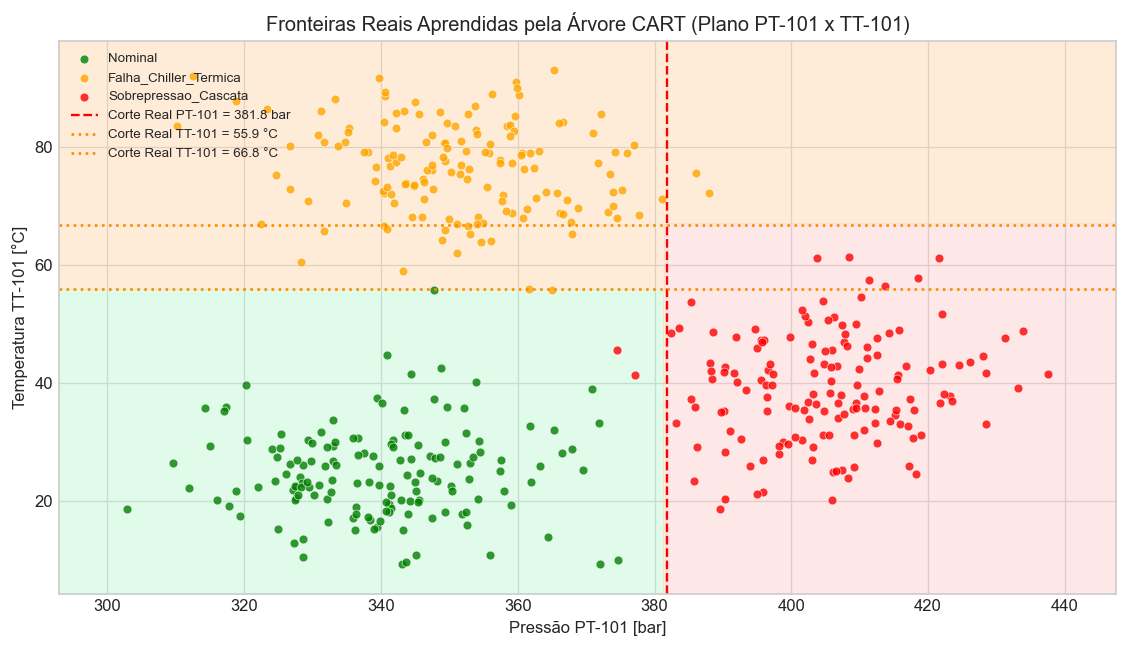

In [5]:
# Treinar modelo 2D (PT-101, TT-101) para extrair fronteiras reais da propria arvore
classes_2d = ["Nominal", "Falha_Chiller_Termica", "Sobrepressao_Cascata"]
df_2d = df[df["Classe"].isin(classes_2d)]
X2 = df_2d[["PT_101_bar", "TT_101_degC"]].values
y2 = df_2d["Classe"].values

clf_2d = ArvoreDecisaoClassica(criterion="gini", max_depth=2)
clf_2d.fit(X2, y2, feature_names=["PT_101_bar", "TT_101_degC"])

xx, yy = np.meshgrid(
    np.linspace(df_2d["PT_101_bar"].min() - 10, df_2d["PT_101_bar"].max() + 10, 220),
    np.linspace(df_2d["TT_101_degC"].min() - 5, df_2d["TT_101_degC"].max() + 5, 220),
)
grid_preds = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
mapa_num = {c: i for i, c in enumerate(classes_2d)}
zz = np.array([mapa_num[p] for p in grid_preds]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#bbf7d0", "#fed7aa", "#fecaca"], alpha=0.45)

cores = {"Nominal": "green", "Falha_Chiller_Termica": "orange", "Sobrepressao_Cascata": "red"}
for classe, cor in cores.items():
    sub = df_2d[df_2d["Classe"] == classe]
    ax.scatter(sub["PT_101_bar"], sub["TT_101_degC"], c=cor, label=classe, alpha=0.8, s=28, edgecolors="white", linewidth=0.4)

# Plotar limiares reais aprendidos pela arvore
def coletar_cortes(no):
    if no is None or no.value is not None:
        return []
    return [(no.feature, no.threshold)] + coletar_cortes(no.left) + coletar_cortes(no.right)

for feat_idx, th in coletar_cortes(clf_2d.root):
    if feat_idx == 0:
        ax.axvline(th, color="red", linestyle="--", linewidth=1.4, label=f"Corte Real PT-101 = {th:.1f} bar")
    else:
        ax.axhline(th, color="darkorange", linestyle=":", linewidth=1.6, label=f"Corte Real TT-101 = {th:.1f} °C")

ax.set_title("Fronteiras Reais Aprendidas pela Árvore CART (Plano PT-101 x TT-101)")
ax.set_xlabel("Pressão PT-101 [bar]")
ax.set_ylabel("Temperatura TT-101 [°C]")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()